# Prithvi-EO-2.0 × OpenEarthMap — 8-class fine-tuning

**Architecture:** Prithvi-EO-2.0-300M ViT backbone (loaded from HuggingFace Hub via `timm`) +
a hand-built UperNet-style decoder, trained from scratch on OEM's 8 land-cover classes.

**Why no `terratorch`?**  
On Kaggle's Python 3.12 / NumPy 2.5 environment, `terratorch` has an
unresolvable circular import (`smp_registry → smp_model_factory → terratorch.datasets.HLSBands`)
that crashes regardless of pip version. We bypass it entirely by pulling the raw ViT weights
directly from the `ibm-nasa-geospatial/Prithvi-EO-2.0-300M` HuggingFace repo and wiring them
into a standard `timm` ViT. This is identical to what `terratorch` does internally.

**Single GPU:** plain `device = torch.device('cuda')` — no `accelerate`, no spawn, no CUDA
re-init issues.

**Dataset path confirmed from your run:**  
`/kaggle/input/datasets/dyiyacao/openearthmap/{images,labels}/`

In [1]:
# ── Cell 1: Install (only what Kaggle doesn't already have) ──────────────────
!pip install -q torchmetrics einops huggingface_hub
# rasterio, timm, torch, numpy, matplotlib, tqdm: pre-installed on Kaggle

In [2]:
# ── Cell 2: Imports & reproducibility ────────────────────────────────────────
import os, glob, random, json, math, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import rasterio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda")   # single GPU — no spawn, no multi-process
print(f"PyTorch : {torch.__version__}")
print(f"CUDA    : {torch.cuda.get_device_name(0)}  {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

PyTorch : 2.10.0+cu128
CUDA    : Tesla T4  15.6 GB


In [3]:
# ── Cell 3: Dataset paths (confirmed from your previous run) ──────────────────
DATASET_ROOT = "/kaggle/input/datasets/dyiyacao/openearthmap"
IMAGES_DIR   = os.path.join(DATASET_ROOT, "images")
LABELS_DIR   = os.path.join(DATASET_ROOT, "labels")

# Verify
assert os.path.isdir(IMAGES_DIR), f"Not found: {IMAGES_DIR}"
assert os.path.isdir(LABELS_DIR), f"Not found: {LABELS_DIR}"
print(f"images/ contents (first level): {os.listdir(IMAGES_DIR)[:5]}")
print(f"labels/ contents (first level): {os.listdir(LABELS_DIR)[:5]}")

images/ contents (first level): ['val', 'train']
labels/ contents (first level): ['val', 'train']


In [4]:
# ── Cell 4: Build train/val split from official folders ──────────────────────
def collect_pairs(split):
    img_root = os.path.join(IMAGES_DIR, split)
    lbl_root = os.path.join(LABELS_DIR, split)
    assert os.path.isdir(img_root), f"Missing: {img_root}"
    assert os.path.isdir(lbl_root), f"Missing: {lbl_root}"

    imgs = sorted(glob.glob(os.path.join(img_root, "**", "*.tif"), recursive=True))
    pairs = []
    miss = 0
    for ip in imgs:
        rel  = os.path.relpath(ip, img_root)
        lp   = os.path.join(lbl_root, rel)
        if os.path.exists(lp):
            pairs.append((ip, lp))
        else:
            miss += 1
    if miss:
        print(f"  {split}: {miss} images had no matching label")
    return pairs

train_pairs = collect_pairs("train")
val_pairs   = collect_pairs("val")

print(f"Train: {len(train_pairs)}  |  Val: {len(val_pairs)}")
assert train_pairs and val_pairs, "Empty split — check paths"

Train: 2149  |  Val: 538


In [5]:
# ── Cell 5: Label diagnostic ──────────────────────────────────────────────────
DIAG_N = min(150, len(train_pairs))
vc: Counter = Counter()
for _, lp in tqdm(random.sample(train_pairs, DIAG_N), desc="Scanning labels"):
    with rasterio.open(lp) as s:
        arr = s.read(1)
    for v, c in zip(*np.unique(arr, return_counts=True)):
        vc[int(v)] += int(c)

total_px = sum(vc.values())
print(f"\nLabel histogram ({DIAG_N} files, {total_px:,} px):")
for v, c in sorted(vc.items()):
    print(f"  value={v:>3d}  {c:>12,d}  ({100*c/total_px:5.2f}%)  {'█'*int(30*c/total_px+.5)}")

Scanning labels:   0%|          | 0/150 [00:00<?, ?it/s]


Label histogram (150 files, 150,677,998 px):
  value=  0     1,283,229  ( 0.85%)  
  value=  1     1,788,021  ( 1.19%)  
  value=  2    29,057,861  (19.28%)  ██████
  value=  3    26,873,244  (17.83%)  █████
  value=  4     9,512,505  ( 6.31%)  ██
  value=  5    30,668,631  (20.35%)  ██████
  value=  6     5,327,737  ( 3.54%)  █
  value=  7    20,869,346  (13.85%)  ████
  value=  8    25,297,424  (16.79%)  █████


In [6]:
# ── Cell 6: Class map & LUT ───────────────────────────────────────────────────
# OEM raw encoding: 1=Bareland … 8=Building, 0=empty/unknown → remap to 0..7
CLASS_NAMES = [
    "Bareland",        # 0
    "Rangeland",       # 1
    "Developed space", # 2
    "Road",            # 3
    "Tree",            # 4
    "Water",           # 5
    "Agriculture",     # 6
    "Building",        # 7
]
CLASS_HEX = ["#800000","#00FF24","#949494","#FFFFFF","#226126","#0045FF","#4BB549","#DE1F07"]
NUM_CLASSES = len(CLASS_NAMES)

def _hex(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0,2,4))
CLASS_COLORS = np.array([_hex(h) for h in CLASS_HEX], dtype=np.uint8)

IGNORE_INDEX = 255
LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)   # everything unknown → ignore
for raw in range(1, NUM_CLASSES + 1):
    LUT[raw] = raw - 1

observed   = set(vc.keys())
unexpected = observed - set(range(NUM_CLASSES + 1))
if unexpected:
    print(f"Unexpected raw label values: {sorted(unexpected)} → folded into ignore")
else:
    print("✓ All raw label values match standard OEM {0..8} convention")
empty_pct = 100 * vc.get(0, 0) / total_px
print(f"  No-data pixels (value=0 → ignore): {empty_pct:.2f}%")

✓ All raw label values match standard OEM {0..8} convention
  No-data pixels (value=0 → ignore): 0.85%


In [7]:
# ── Cell 7: Dataset class ─────────────────────────────────────────────────────
CROP_SIZE = 224   # divisible by Prithvi's patch_size=16; fits in 16 GB T4

class OEMDataset(Dataset):
    def __init__(self, pairs, train=True, mean=None, std=None, crop=CROP_SIZE):
        self.pairs = pairs
        self.train = train
        self.crop  = crop
        self.mean  = np.array(mean, np.float32) if mean is not None else np.array([119., 121., 106.], np.float32)
        self.std   = np.array(std,  np.float32) if std  is not None else np.array([51.,  47.,  48. ], np.float32)

    def __len__(self): return len(self.pairs)

    def _crop(self, img, lbl):
        _, h, w = img.shape
        cs = self.crop
        if h < cs or w < cs:
            ph, pw = max(0, cs-h), max(0, cs-w)
            img = np.pad(img, ((0,0),(0,ph),(0,pw)), "reflect")
            lbl = np.pad(lbl, ((0,ph),(0,pw)),       "reflect")
            _, h, w = img.shape
        top  = random.randint(0, h-cs) if self.train else (h-cs)//2
        left = random.randint(0, w-cs) if self.train else (w-cs)//2
        return img[:, top:top+cs, left:left+cs], lbl[top:top+cs, left:left+cs]

    def __getitem__(self, idx):
        ip, lp = self.pairs[idx]
        with rasterio.open(ip) as s:
            img = s.read([1,2,3]).astype(np.float32)   # (3,H,W) RGB
        with rasterio.open(lp) as s:
            raw = s.read(1).astype(np.uint8)            # (H,W)

        img, raw = self._crop(img, raw)

        if self.train:
            if random.random() < .5: img = img[:,:,::-1].copy(); raw = raw[:,::-1].copy()
            if random.random() < .5: img = img[:,::-1,:].copy(); raw = raw[::-1,:].copy()
            k = random.randint(0,3)
            if k: img = np.rot90(img,k,(1,2)).copy(); raw = np.rot90(raw,k,(0,1)).copy()

        lbl = LUT[raw].astype(np.int64)   # 0..7 valid, 255 = ignore
        img = (img - self.mean[:,None,None]) / (self.std[:,None,None] + 1e-6)
        return torch.from_numpy(img.astype(np.float32)), torch.from_numpy(lbl)

In [9]:
# ── Cell 8: Dataset statistics & class weights ────────────────────────────────
STATS_N = min(300, len(train_pairs))
psum = np.zeros(3, np.float64)
psum2 = np.zeros(3, np.float64)
pcount = 0
class_counts = np.zeros(NUM_CLASSES, np.int64)   # ← must be defined BEFORE the loop

for ip, lp in tqdm(random.sample(train_pairs, STATS_N), desc="Stats"):
    with rasterio.open(ip) as s:
        img = s.read([1, 2, 3]).astype(np.float64)
    with rasterio.open(lp) as s:
        raw = s.read(1).astype(np.uint8)

    psum  += img.sum(axis=(1, 2))
    psum2 += (img ** 2).sum(axis=(1, 2))
    pcount += img.shape[1] * img.shape[2]

    mapped = LUT[raw].ravel()
    valid  = mapped[mapped != IGNORE_INDEX]
    class_counts += np.bincount(valid, minlength=NUM_CLASSES)

DATA_MEAN = (psum / pcount).astype(np.float32)
DATA_STD  = np.sqrt(np.maximum(psum2 / pcount - (psum / pcount) ** 2, 0)).astype(np.float32)
print(f"Mean (R,G,B): {DATA_MEAN}")
print(f"Std  (R,G,B): {DATA_STD}")

print("\nClass distribution (ignore pixels excluded):")
for n, c in zip(CLASS_NAMES, class_counts):
    print(f"  {n:<18s} {100 * c / class_counts.sum():.2f}%")

freq = class_counts / class_counts.sum()
CLASS_WEIGHTS = (1.0 / np.sqrt(freq + 1e-6)).astype(np.float32)
CLASS_WEIGHTS /= CLASS_WEIGHTS.mean()
print("\nClass weights:", dict(zip(CLASS_NAMES, CLASS_WEIGHTS.round(3))))

Stats:   0%|          | 0/300 [00:00<?, ?it/s]

Mean (R,G,B): [118.53529 121.59473 106.70677]
Std  (R,G,B): [50.936897 46.308495 48.134945]

Class distribution (ignore pixels excluded):
  Bareland           2.07%
  Rangeland          21.90%
  Developed space    18.61%
  Road               7.22%
  Tree               19.69%
  Water              3.04%
  Agriculture        10.85%
  Building           16.61%

Class weights: {'Bareland': np.float32(1.943), 'Rangeland': np.float32(0.598), 'Developed space': np.float32(0.648), 'Road': np.float32(1.041), 'Tree': np.float32(0.63), 'Water': np.float32(1.604), 'Agriculture': np.float32(0.849), 'Building': np.float32(0.686)}


In [10]:
# ── Cell 9: Loss ──────────────────────────────────────────────────────────────
class DiceLoss(nn.Module):
    def __init__(self, nc, ignore_index=255, eps=1e-6):
        super().__init__()
        self.nc = nc
        self.ignore_index = ignore_index
        self.eps = eps

    def forward(self, logits, tgt):
        p = F.softmax(logits, 1)

        valid = (tgt != self.ignore_index)                 # (B,H,W)
        tgt_c = tgt.clone()
        tgt_c[~valid] = 0                                  # dummy class, masked below

        oh = F.one_hot(tgt_c, self.nc).permute(0, 3, 1, 2).float()  # (B,C,H,W)
        m  = valid.unsqueeze(1).float()                    # (B,1,H,W)
        p  = p * m
        oh = oh * m

        i = (p * oh).sum((0, 2, 3))
        c = (p + oh).sum((0, 2, 3))
        return (1 - (2 * i + self.eps) / (c + self.eps)).mean()


class CEDiceLoss(nn.Module):
    def __init__(self, nc, weights=None, ignore_index=255):
        super().__init__()
        w = torch.tensor(weights, dtype=torch.float32) if weights is not None else None
        self.ce = nn.CrossEntropyLoss(
            weight=w, ignore_index=ignore_index, label_smoothing=0.05
        )
        self.dice = DiceLoss(nc, ignore_index=ignore_index)

    def forward(self, logits, tgt):
        return self.ce(logits, tgt) + self.dice(logits, tgt)

In [11]:
# ── Cell 10: Model — Prithvi ViT backbone + UperNet decoder ───────────────────
# We load the Prithvi-EO-2.0-300M MAE-pretrained backbone weights directly from
# HuggingFace Hub without using terratorch at all.

import timm
from huggingface_hub import hf_hub_download
from einops import rearrange

# --------------------------------------------------------------------------
# 10a. Backbone: standard timm ViT-Large (same arch as Prithvi-300M)
#      patch_size=16, embed_dim=1024, depth=24, num_heads=16
# --------------------------------------------------------------------------
def make_backbone(img_size=CROP_SIZE):
    """Build a timm ViT-Large backbone matching Prithvi-EO-2.0-300M's architecture."""
    model = timm.create_model(
        "vit_large_patch16_224",
        pretrained=False,
        img_size=img_size,
        in_chans=3,
        num_classes=0,          # remove classification head
        global_pool="",         # return all tokens, not pooled
    )
    return model


def load_prithvi_weights(backbone, img_size=CROP_SIZE):
    """Download Prithvi-EO-2.0-300M MAE weights and adapt them to our timm ViT."""
    print("Downloading Prithvi-EO-2.0-300M weights from HuggingFace Hub...")
    ckpt_path = hf_hub_download(
        repo_id="ibm-nasa-geospatial/Prithvi-EO-2.0-300M",
        filename="Prithvi_EO_V2_300M.pt",
    )
    print(f"  Downloaded to: {ckpt_path}")

    ckpt = torch.load(ckpt_path, map_location="cpu")
    # The checkpoint may be a plain state_dict or a nested dict
    state = ckpt.get("state_dict", ckpt.get("model", ckpt))

    # ── Key mapping: MAE key prefixes → timm key names ──────────────────────
    # MAE uses 'encoder.' prefix; timm uses no prefix.
    # Additionally Prithvi uses 6 input bands; we only feed 3 (RGB), so we
    # sub-select the first 3 input channels of the patch_embed projection.
    remap = {}
    for k, v in state.items():
        # Strip common prefixes
        nk = k
        for prefix in ["encoder.", "model.encoder.", "backbone."]:
            if nk.startswith(prefix):
                nk = nk[len(prefix):]
                break

        # Skip MAE-only keys (decoder, mask_token, etc.)
        if any(x in nk for x in ["decoder", "mask_token", "pred"]):
            continue

        # patch_embed.proj.weight: (embed_dim, in_chans, ph, pw)
        # Prithvi has in_chans=6 (or 3×T); timm ViT has in_chans=3.
        # Prithvi also adds a temporal dimension T making it
        # (embed_dim, C, T, ph, pw) in some checkpoints.
        if "patch_embed.proj.weight" in nk:
            if v.ndim == 5:           # (D, C, T, ph, pw) → collapse T, take first 3 channels
                v = v[:, :, 0, :, :]  # take T=0
            if v.shape[1] > 3:        # take first 3 input channels (Blue,Green,Red or R,G,B)
                v = v[:, :3, :, :]
            if v.shape[1] < 3:        # if only 1 or 2 bands were present, repeat
                v = v.repeat(1, math.ceil(3/v.shape[1]), 1, 1)[:, :3, :, :]

        # pos_embed: (1, N_patches+1, D). If img_size changed, interpolate.
        if "pos_embed" in nk and v.shape != backbone.pos_embed.shape:
            src = v[:, 1:, :]   # strip CLS token
            gs_old = int(math.sqrt(src.shape[1]))
            gs_new = img_size // 16
            if gs_old != gs_new:
                src = src.reshape(1, gs_old, gs_old, -1).permute(0,3,1,2).float()
                src = F.interpolate(src, size=(gs_new, gs_new), mode="bicubic", align_corners=False)
                src = src.permute(0,2,3,1).reshape(1, gs_new*gs_new, -1)
            v = torch.cat([v[:, :1, :], src], dim=1)

        remap[nk] = v

    missing, unexpected = backbone.load_state_dict(remap, strict=False)
    # Filter out known non-critical missing keys
    critical_missing = [k for k in missing if not any(
        x in k for x in ["norm", "head", "fc_norm"]
    )]
    print(f"  Loaded Prithvi weights: {len(remap)} keys matched")
    print(f"  Missing  (total {len(missing)}, critical {len(critical_missing)}): {critical_missing[:5]}")
    print(f"  Unexpected: {len(unexpected)}")
    if len(critical_missing) > 10:
        print("  WARNING: many critical keys missing — weight loading likely failed. Check repo filename.")
    return backbone


# --------------------------------------------------------------------------
# 10b. UperNet-style decoder
# Extracts features from 4 ViT transformer blocks (indices 5,11,17,23),
# reshapes tokens → feature maps, runs FPN + PPM head.
# --------------------------------------------------------------------------
class ViTFeatureExtractor(nn.Module):
    """Hooks into a timm ViT and returns intermediate block outputs."""
    LAYER_INDICES = [5, 11, 17, 23]   # 4 stages from a 24-block ViT-L

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.patch_size = backbone.patch_embed.patch_size[0]   # 16
        self.embed_dim  = backbone.embed_dim                    # 1024

    def forward(self, x):
        """Returns (list of 4 feature maps, each (B, D, H//16, W//16))."""
        B, C, H, W = x.shape
        ps = self.patch_size
        gh, gw = H // ps, W // ps

        # Standard timm forward up to patch embed + pos embed
        x = self.backbone.patch_embed(x)                   # (B, N, D)
        x = self.backbone._pos_embed(x)                    # adds CLS + pos embed
        x = self.backbone.patch_drop(x)
        x = self.backbone.norm_pre(x)

        features = []
        for i, block in enumerate(self.backbone.blocks):
            x = block(x)
            if i in self.LAYER_INDICES:
                tokens = x[:, 1:, :]             # strip CLS
                fmap   = tokens.reshape(B, gh, gw, self.embed_dim).permute(0,3,1,2)  # (B,D,H,W)
                features.append(fmap)

        return features   # 4 × (B, 1024, 14, 14) for 224px input


class PPM(nn.Module):
    """Pyramid Pooling Module (from PSPNet / UperNet)."""
    def __init__(self, in_dim, reduction_dim=256, bins=(1,2,3,6)):
        super().__init__()
        self.stages = nn.ModuleList([
            nn.Sequential(
                nn.AdaptiveAvgPool2d(b),
                nn.Conv2d(in_dim, reduction_dim, 1, bias=False),
                nn.BatchNorm2d(reduction_dim),
                nn.ReLU(inplace=True),
            ) for b in bins
        ])

    def forward(self, x):
        h, w = x.shape[-2:]
        out  = [x]
        for s in self.stages:
            out.append(F.interpolate(s(x), size=(h,w), mode="bilinear", align_corners=False))
        return torch.cat(out, dim=1)


class UperDecoder(nn.Module):
    """UperNet-style decoder for a 4-stage ViT feature pyramid."""
    def __init__(self, in_dim=1024, fpn_dim=256, num_classes=8):
        super().__init__()
        # Lateral projections (4 FPN levels)
        self.laterals = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_dim, fpn_dim, 1, bias=False),
                nn.BatchNorm2d(fpn_dim), nn.ReLU(inplace=True),
            ) for _ in range(4)
        ])
        # FPN top-down
        self.fpn_convs = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(fpn_dim, fpn_dim, 3, padding=1, bias=False),
                nn.BatchNorm2d(fpn_dim), nn.ReLU(inplace=True),
            ) for _ in range(4)
        ])
        # PPM on deepest feature
        self.ppm = PPM(in_dim, fpn_dim)
        ppm_out_dim = in_dim + 4 * fpn_dim
        self.ppm_bottleneck = nn.Sequential(
            nn.Conv2d(ppm_out_dim, fpn_dim, 3, padding=1, bias=False),
            nn.BatchNorm2d(fpn_dim), nn.ReLU(inplace=True),
        )
        # Fuse all FPN levels
        self.fuse = nn.Sequential(
            nn.Conv2d(4*fpn_dim, fpn_dim, 3, padding=1, bias=False),
            nn.BatchNorm2d(fpn_dim), nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
        )
        self.head = nn.Conv2d(fpn_dim, num_classes, 1)

    def forward(self, feats, out_size):
        """feats: list of 4 feature maps (B,D,h,w). out_size: (H,W) of input image."""
        # PPM on deepest
        p = self.ppm_bottleneck(self.ppm(feats[-1]))

        # Lateral + FPN top-down
        laterals = [l(f) for l, f in zip(self.laterals, feats)]
        laterals[-1] = p
        for i in range(2, -1, -1):
            laterals[i] = laterals[i] + F.interpolate(
                laterals[i+1], size=laterals[i].shape[-2:], mode="bilinear", align_corners=False
            )
        fpn_outs = [c(l) for c, l in zip(self.fpn_convs, laterals)]

        # Upsample all to level-0 resolution, fuse
        ref_size = fpn_outs[0].shape[-2:]
        fused = torch.cat([
            F.interpolate(f, size=ref_size, mode="bilinear", align_corners=False)
            for f in fpn_outs
        ], dim=1)
        fused = self.fuse(fused)

        # Upsample to input resolution
        logits = F.interpolate(self.head(fused), size=out_size, mode="bilinear", align_corners=False)
        return logits


class PrithviSegModel(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, img_size=CROP_SIZE, pretrained=True):
        super().__init__()
        backbone = make_backbone(img_size)
        if pretrained:
            backbone = load_prithvi_weights(backbone, img_size)
        self.encoder = ViTFeatureExtractor(backbone)
        self.decoder = UperDecoder(in_dim=1024, fpn_dim=256, num_classes=num_classes)

    def forward(self, x):
        H, W = x.shape[-2:]
        feats  = self.encoder(x)          # list of 4 feature maps
        logits = self.decoder(feats, (H, W))
        return logits


def set_backbone_grad(model, trainable):
    for n, p in model.encoder.backbone.named_parameters():
        p.requires_grad = trainable
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    print(f"  Backbone {'TRAINABLE' if trainable else 'FROZEN'}  |  {tr:,}/{tot:,} params trainable")

In [12]:
# ── Cell 11: Training loop (single GPU, plain PyTorch) ────────────────────────
def _quick_miou(model, loader, num_classes, ignore_index=255):
    """Fast mIoU on the val loader, used for checkpoint selection."""
    model.eval()
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(DEVICE)
            with torch.amp.autocast('cuda'):
                logits = model(imgs)
            if logits.shape[-2:] != lbls.shape[-2:]:
                logits = F.interpolate(logits, lbls.shape[-2:],
                                       mode="bilinear", align_corners=False)
            preds = logits.argmax(1).cpu().numpy().ravel()
            tgts  = lbls.numpy().ravel()
            mask  = tgts != ignore_index
            np.add.at(cm, (tgts[mask], preds[mask]), 1)
    tp  = np.diag(cm).astype(np.float64)
    fp  = cm.sum(0) - tp
    fn  = cm.sum(1) - tp
    iou = tp / (tp + fp + fn + 1e-6)
    return iou.mean(), iou


def train(
    train_pairs, val_pairs, *,
    num_classes   = NUM_CLASSES,
    crop_size     = CROP_SIZE,
    batch_size    = 4,
    num_workers   = 2,
    freeze_epochs = 5,
    total_epochs  = 40,
    lr_backbone   = 2e-5,
    lr_decoder    = 1e-3,
    patience      = 10,
    ckpt_dir      = "/kaggle/working/checkpoints",
    mean          = None,
    std           = None,
    class_weights = None,
):
    os.makedirs(ckpt_dir, exist_ok=True)

    tr_ds = OEMDataset(train_pairs, train=True,  mean=mean, std=std, crop=crop_size)
    va_ds = OEMDataset(val_pairs,   train=False, mean=mean, std=std, crop=crop_size)
    tr_dl = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers,
                       pin_memory=True, drop_last=True,  persistent_workers=num_workers>0)
    va_dl = DataLoader(va_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers,
                       pin_memory=True, persistent_workers=num_workers>0)

    model = PrithviSegModel(num_classes=num_classes, img_size=crop_size, pretrained=True)
    model = model.to(DEVICE)

    criterion = CEDiceLoss(num_classes, weights=class_weights, ignore_index=IGNORE_INDEX)
    criterion = criterion.to(DEVICE)

    # Differential LR: backbone small, decoder larger
    optimizer = torch.optim.AdamW([
        {"params": model.encoder.backbone.parameters(), "lr": lr_backbone},
        {"params": model.decoder.parameters(),          "lr": lr_decoder},
    ], weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=total_epochs, eta_min=1e-6
    )
    scaler = torch.amp.GradScaler('cuda')

    best_miou = -1.0
    epochs_since_improve = 0
    history = {"train_loss": [], "val_loss": [], "val_miou": []}

    for epoch in range(total_epochs):
        phase_frozen = epoch < freeze_epochs

        if epoch == 0 or epoch == freeze_epochs:
            set_backbone_grad(model, trainable=not phase_frozen)

        # ── train ────────────────────────────────────────────────────────────
        model.train()
        run_loss = 0.0
        tag = "frozen" if phase_frozen else "finetune"
        pbar = tqdm(tr_dl, desc=f"Ep {epoch+1}/{total_epochs} [{tag}]", leave=False)
        for imgs, lbls in pbar:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                logits = model(imgs)
                loss   = criterion(logits, lbls)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            run_loss += loss.item()
            pbar.set_postfix(loss=f"{run_loss/(pbar.n+1):.4f}")
        scheduler.step()
        train_loss = run_loss / max(len(tr_dl), 1)

        # ── val loss ─────────────────────────────────────────────────────────
        model.eval()
        val_sum, val_n = 0.0, 0
        with torch.no_grad():
            for imgs, lbls in va_dl:
                imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
                with torch.amp.autocast('cuda'):
                    logits = model(imgs)
                    val_sum += criterion(logits, lbls).item()
                val_n += 1
        val_loss = val_sum / max(val_n, 1)

        # ── val mIoU (checkpoint selector) ───────────────────────────────────
        val_miou, per_class_iou = _quick_miou(model, va_dl, num_classes, IGNORE_INDEX)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_miou"].append(float(val_miou))

        lr_now = optimizer.param_groups[-1]["lr"]
        print(f"Epoch {epoch+1:>3d}/{total_epochs}  "
              f"train={train_loss:.4f}  val={val_loss:.4f}  "
              f"mIoU={val_miou:.4f}  lr={lr_now:.2e}")

        torch.save(model.state_dict(), os.path.join(ckpt_dir, "last.pt"))

        if val_miou > best_miou:
            best_miou = val_miou
            epochs_since_improve = 0
            torch.save(model.state_dict(), os.path.join(ckpt_dir, "best.pt"))
            print(f"  ✓ best saved (mIoU={val_miou:.4f})")
        else:
            epochs_since_improve += 1
            if epochs_since_improve >= patience:
                print(f"\nEarly stopping: no mIoU improvement for {patience} epochs.")
                break

        with open(os.path.join(ckpt_dir, "history.json"), "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nTraining complete. Best val mIoU = {best_miou:.4f}")
    return model, history

In [13]:
# ── Cell 12: Run training ─────────────────────────────────────────────────────
model, history = train(
    train_pairs,
    val_pairs,
    num_classes   = NUM_CLASSES,
    crop_size     = CROP_SIZE,
    batch_size    = 4,
    num_workers   = 2,
    freeze_epochs = 5,
    total_epochs  = 40,       # was 15
    lr_backbone   = 2e-5,     # was 5e-5 uniform
    lr_decoder    = 1e-3,     # was 1e-3 then 5e-5
    patience      = 10,
    ckpt_dir      = "/kaggle/working/checkpoints",
    mean          = DATA_MEAN.tolist(),
    std           = DATA_STD.tolist(),
    class_weights = CLASS_WEIGHTS.tolist(),
)

Prithvi_EO_V2_300M.pt:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

  Downloaded to: /root/.cache/huggingface/hub/models--ibm-nasa-geospatial--Prithvi-EO-2.0-300M/snapshots/9eb1b1102806593963daa333bcc491b1c6f8562f/Prithvi_EO_V2_300M.pt
  Loaded Prithvi weights: 294 keys matched
  Missing  (total 0, critical 0): []
  Unexpected: 0
  Backbone FROZEN  |  11,543,560/314,845,192 params trainable


Ep 1/40 [frozen]:   0%|          | 0/537 [00:00<?, ?it/s]

Epoch   1/40  train=2.5610  val=2.3015  mIoU=0.2809  lr=9.98e-04
  ✓ best saved (mIoU=0.2809)


Ep 2/40 [frozen]:   0%|          | 0/537 [00:00<?, ?it/s]

...

Epoch  38/40  train=1.4267  val=1.5430  mIoU=0.5910  lr=7.15e-06


Ep 39/40 [finetune]:   0%|          | 0/537 [00:00<?, ?it/s]

Epoch  39/40  train=1.4009  val=1.5479  mIoU=0.5907  lr=2.54e-06


Ep 40/40 [finetune]:   0%|          | 0/537 [00:00<?, ?it/s]

Epoch  40/40  train=1.4061  val=1.5535  mIoU=0.5999  lr=1.00e-06
  ✓ best saved (mIoU=0.5999)

Training complete. Best val mIoU = 0.5999


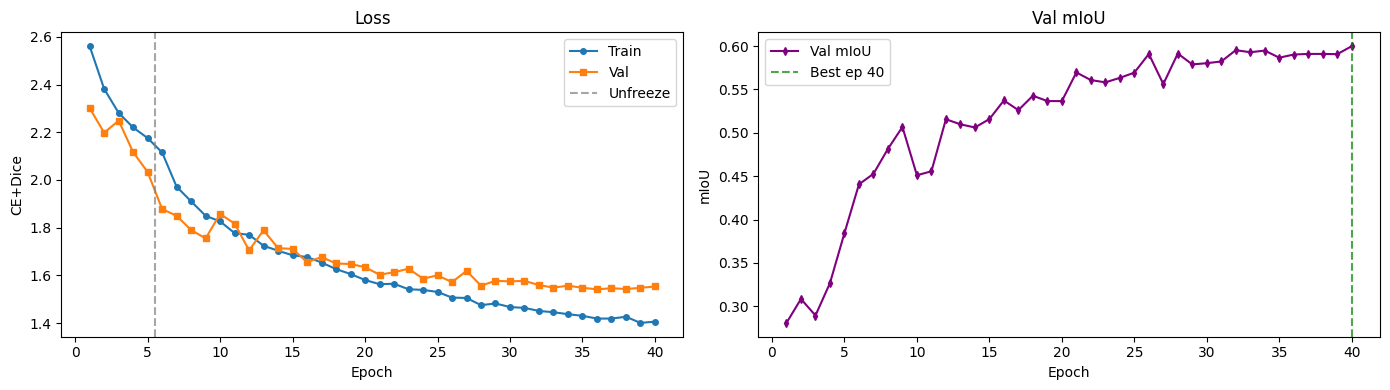

In [14]:
# ── Cell 13: Training curve ───────────────────────────────────────────────────
epochs_x = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(epochs_x, history["train_loss"], "o-", ms=4, label="Train")
ax1.plot(epochs_x, history["val_loss"],   "s-", ms=4, label="Val")
ax1.axvline(5.5, color="grey", ls="--", alpha=.7, label="Unfreeze")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("CE+Dice"); ax1.set_title("Loss")
ax1.legend()

ax2.plot(epochs_x, history["val_miou"], "d-", ms=4, color="purple", label="Val mIoU")
best_ep = int(np.argmax(history["val_miou"])) + 1
ax2.axvline(best_ep, color="green", ls="--", alpha=.7, label=f"Best ep {best_ep}")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("mIoU"); ax2.set_title("Val mIoU")
ax2.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/training_curve.png", dpi=150)
plt.show()

In [15]:
!pip install -q einops huggingface_hub

### Replace Cell 14 entirely — no torchmetrics import

# ── Cell 14: Load best checkpoint ────────────────────────────────────────────
CKPT = "/kaggle/working/checkpoints/best.pt"
eval_model = PrithviSegModel(num_classes=NUM_CLASSES, img_size=CROP_SIZE, pretrained=False)
sd = torch.load(CKPT, map_location="cpu")
missing, unexpected = eval_model.load_state_dict(sd, strict=True)
assert not missing and not unexpected, f"Mismatch: missing={missing[:3]}, unexpected={unexpected[:3]}"
eval_model = eval_model.to(DEVICE).eval()
print("✓ best.pt loaded")

✓ best.pt loaded


In [16]:
### Replace Cell 15 entirely - pure numpy metrics

# — Cell 15: Metrics (pure numpy, no torchmetrics/scipy) ———————————
va_ds_eval = OEMDataset(val_pairs, train=False, mean=DATA_MEAN.tolist(), std=DATA_STD.tolist())
va_dl_eval = DataLoader(va_ds_eval, batch_size=8, shuffle=False, num_workers=2)

# Accumulate confusion matrix
cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
with torch.no_grad():
    for imgs, lbls in tqdm(va_dl_eval, desc="Evaluating"):
        imgs = imgs.to(DEVICE)
        with torch.cuda.amp.autocast():
            logits = eval_model(imgs)
        if logits.shape[-2:] != lbls.shape[-2:]:
            logits = F.interpolate(logits, lbls.shape[-2:], mode="bilinear", align_corners=False)
        preds = logits.argmax(1).cpu().numpy().ravel()
        lbls  = lbls.numpy().ravel()
        mask  = lbls != IGNORE_INDEX
        np.add.at(cm, (lbls[mask], preds[mask]), 1)

# Derive all metrics from confusion matrix
tp = np.diag(cm).astype(np.float64)
fp = cm.sum(0) - tp
fn = cm.sum(1) - tp
eps = 1e-6

per_iou = tp / (tp + fp + fn + eps)
mean_iou = per_iou.mean()
per_prec = tp / (tp + fp + eps)
per_rec = tp / (tp + fn + eps)
per_f1 = 2 * per_prec * per_rec / (per_prec + per_rec + eps)
oacc = tp.sum() / cm.sum()
confmat = cm / (cm.sum(1, keepdims=True) + eps)  # row-normalised

print(f"\n{'='*65}")
print(f" Pixel accuracy : {oacc:.4f}")
print(f" mIoU           : {mean_iou:.4f}")
print(f"{'='*65}")
print(f"{'Class':<20} {'IoU':>8} {'F1':>8} {'Prec':>8} {'Rec':>8}")
print("-"*56)
for i, n in enumerate(CLASS_NAMES):
    print(f"{n:<20} {per_iou[i]:8.4f} {per_f1[i]:8.4f} {per_prec[i]:8.4f} {per_rec[i]:8.4f}")

report = {"pixel_accuracy": oacc, "mIoU": mean_iou, "per_class": {
    n: {"iou": float(per_iou[i]), "f1": float(per_f1[i]),
        "precision": float(per_prec[i]), "recall": float(per_rec[i])}
    for i, n in enumerate(CLASS_NAMES)}}
with open("/kaggle/working/metrics_report.json", "w") as f:
    json.dump(report, f, indent=2)
print("\n✓ metrics_report.json saved")

Evaluating:   0%|          | 0/68 [00:00<?, ?it/s]

/tmp/ipykernel_58/1464228180.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



 Pixel accuracy : 0.7437
 mIoU           : 0.5999
Class                     IoU       F1     Prec      Rec
--------------------------------------------------------
Bareland               0.4055   0.5770   0.5588   0.5965
Rangeland              0.5111   0.6765   0.6724   0.6806
Developed space        0.4866   0.6547   0.6506   0.6588
Road                   0.5555   0.7143   0.6779   0.7547
Tree                   0.6311   0.7739   0.7801   0.7677
Water                  0.7866   0.8805   0.9121   0.8510
Agriculture            0.6927   0.8184   0.8706   0.7721
Building               0.7304   0.8442   0.8344   0.8542

✓ metrics_report.json saved


/tmp/ipykernel_58/3362034010.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(CLASS_NAMES, rotation=35, ha="right", fontsize=9)


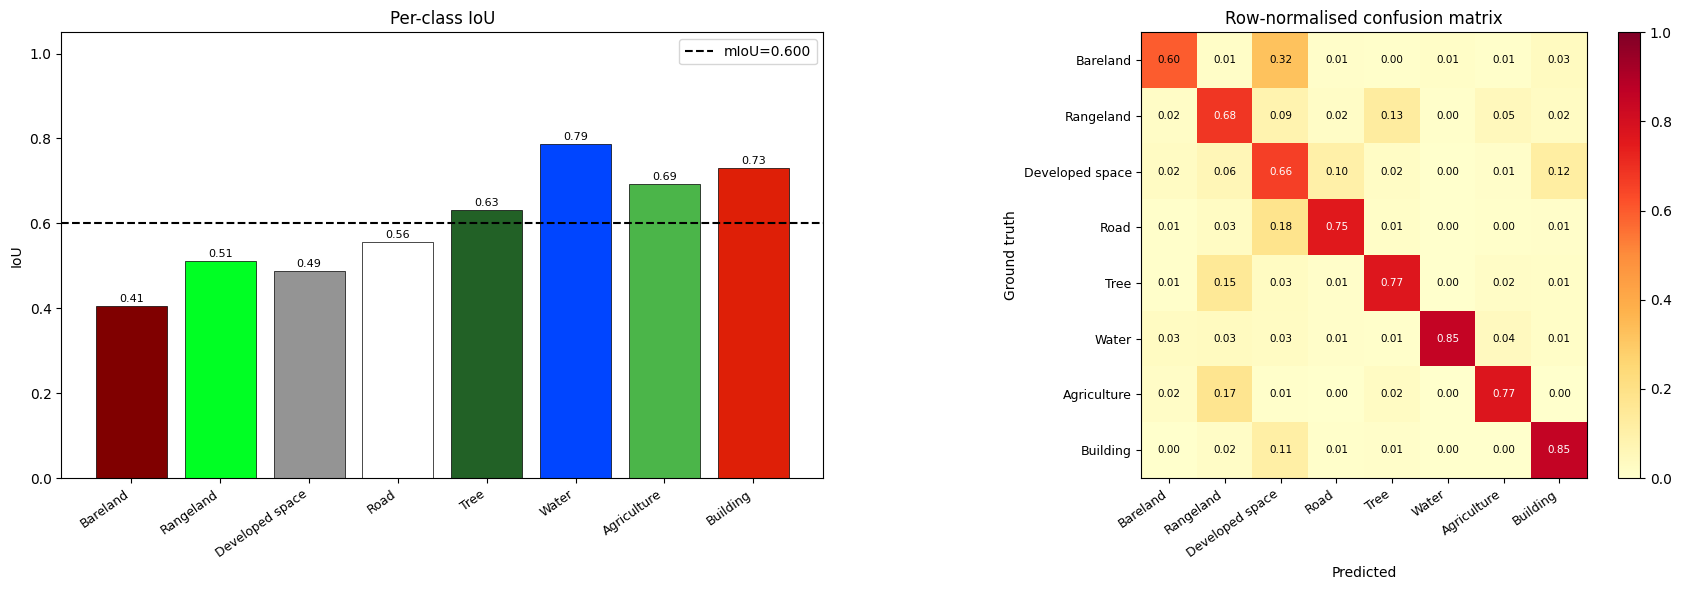

✓ metrics_plots.png


In [17]:
# ── Cell 16: Metrics plots ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# IoU bar chart
bcolors = [CLASS_COLORS[i]/255 for i in range(NUM_CLASSES)]
bars = axes[0].bar(CLASS_NAMES, per_iou, color=bcolors, edgecolor="k", lw=0.5)
axes[0].axhline(mean_iou, color="k", ls="--", lw=1.5, label=f"mIoU={mean_iou:.3f}")
for bar, v in zip(bars, per_iou):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f"{v:.2f}", ha="center", va="bottom", fontsize=8)
axes[0].set_ylim(0,1.05); axes[0].set_ylabel("IoU")
axes[0].set_title("Per-class IoU"); axes[0].legend()
axes[0].set_xticklabels(CLASS_NAMES, rotation=35, ha="right", fontsize=9)

# Confusion matrix
im = axes[1].imshow(confmat, cmap="YlOrRd", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        axes[1].text(j, i, f"{confmat[i,j]:.2f}", ha="center", va="center",
                     fontsize=7.5, color="white" if confmat[i,j]>.6 else "black")
axes[1].set_xticks(range(NUM_CLASSES)); axes[1].set_yticks(range(NUM_CLASSES))
axes[1].set_xticklabels(CLASS_NAMES, rotation=35, ha="right", fontsize=9)
axes[1].set_yticklabels(CLASS_NAMES, fontsize=9)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Ground truth")
axes[1].set_title("Row-normalised confusion matrix")
fig.colorbar(im, ax=axes[1], fraction=.046, pad=.04)
plt.tight_layout()
plt.savefig("/kaggle/working/metrics_plots.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ metrics_plots.png")

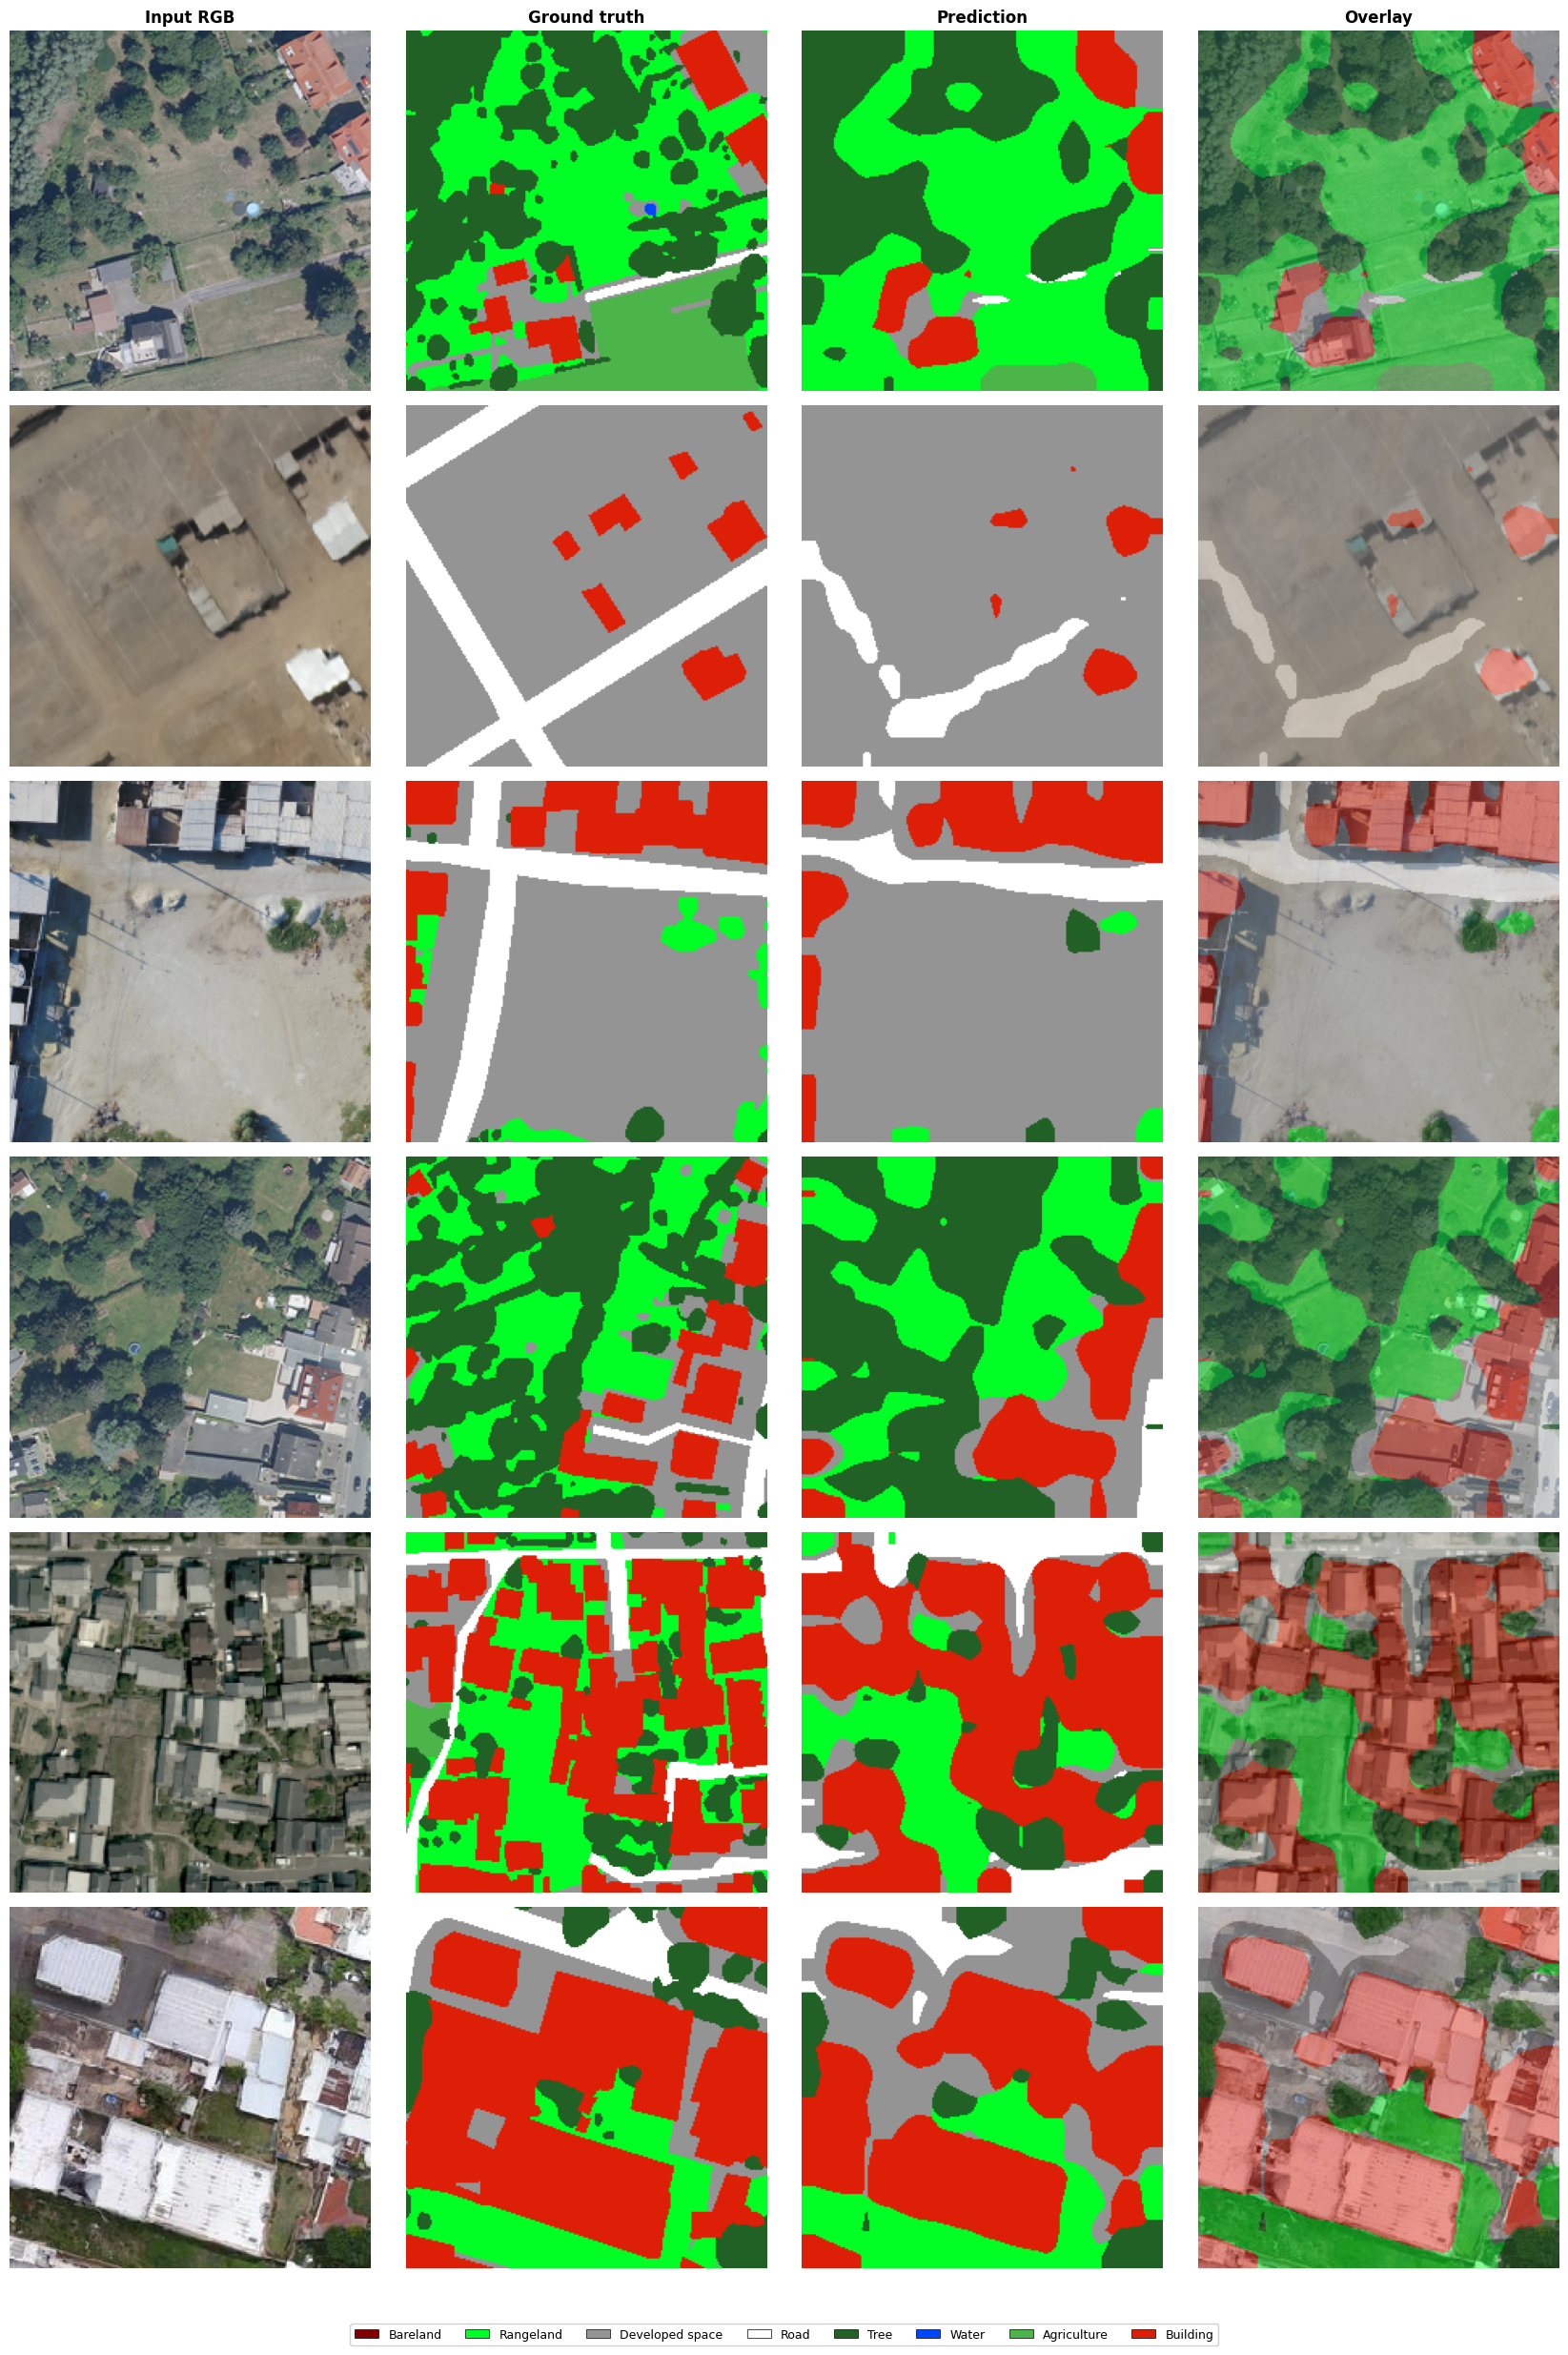

✓ visual_comparison.png


In [18]:
# ── Cell 17: Visual comparison ────────────────────────────────────────────────
def colorize(lbl): return CLASS_COLORS[lbl]
def denorm(t, mean, std):
    img = t * std[:,None,None] + mean[:,None,None]
    return np.clip(img,0,255).astype(np.uint8).transpose(1,2,0)

N = 6
idxs = random.sample(range(len(va_ds_eval)), min(N, len(va_ds_eval)))
fig, axes = plt.subplots(len(idxs), 4, figsize=(17, 4*len(idxs)))
if len(idxs)==1: axes=axes[None,:]
for col,t in enumerate(["Input RGB","Ground truth","Prediction","Overlay"]):
    axes[0,col].set_title(t, fontsize=12, fontweight="bold")

mean_np = DATA_MEAN; std_np = DATA_STD
with torch.no_grad():
    for row, idx in enumerate(idxs):
        img_t, lbl_t = va_ds_eval[idx]
        with torch.amp.autocast('cuda'):
            logits = eval_model(img_t.unsqueeze(0).to(DEVICE))
        pred = logits.argmax(1).squeeze().cpu().numpy()

        rgb      = denorm(img_t.numpy(), mean_np, std_np)
        gt_col   = colorize(lbl_t.numpy())
        pr_col   = colorize(pred)

        axes[row,0].imshow(rgb);     axes[row,0].axis("off")
        axes[row,1].imshow(gt_col);  axes[row,1].axis("off")
        axes[row,2].imshow(pr_col);  axes[row,2].axis("off")
        axes[row,3].imshow(rgb); axes[row,3].imshow(pr_col, alpha=.45); axes[row,3].axis("off")

        gt_f = lbl_t.numpy().ravel()
        ious = [np.logical_and(pred.ravel()==c, gt_f==c).sum()/
                max(np.logical_or(pred.ravel()==c, gt_f==c).sum(),1) for c in range(NUM_CLASSES)]
        axes[row,0].set_ylabel(f"mIoU={np.mean(ious):.2f}", fontsize=9, rotation=0, labelpad=60)

patches = [mpatches.Patch(fc=CLASS_COLORS[i]/255, ec="k", lw=.5, label=CLASS_NAMES[i])
           for i in range(NUM_CLASSES)]
fig.legend(handles=patches, loc="lower center", ncol=NUM_CLASSES,
           bbox_to_anchor=(.5,-.03), fontsize=9, framealpha=.9)
plt.tight_layout()
plt.savefig("/kaggle/working/visual_comparison.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ visual_comparison.png")

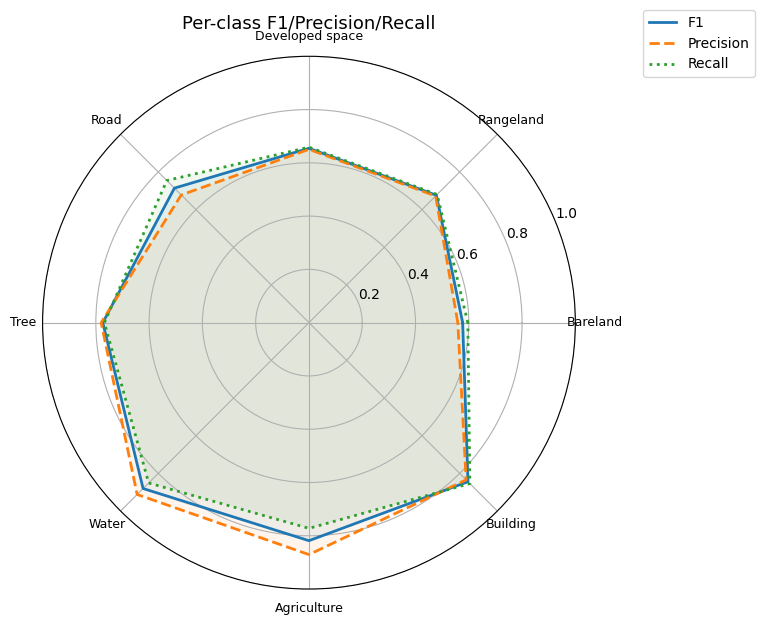

✓ radar_chart.png


In [20]:
# ── Cell 18: Radar chart ──────────────────────────────────────────────────────
angles = np.linspace(0, 2*np.pi, NUM_CLASSES, endpoint=False).tolist()
ac = angles + angles[:1]
fig, ax = plt.subplots(figsize=(8,8), subplot_kw=dict(polar=True))
for vals, lbl, color, ls in [
    (per_f1,   "F1",        "#1f77b4", "-"),
    (per_prec, "Precision", "#2ca02c", "--"),
    (per_rec,  "Recall",    "#d62728", ":"),
]:
    vc = vals.tolist() + vals[:1].tolist()
    ax.plot(ac, vc, ls=ls, lw=2, label=lbl)
    ax.fill(ac, vc, alpha=.07)
ax.set_xticks(angles); ax.set_xticklabels(CLASS_NAMES, fontsize=9)
ax.set_ylim(0,1); ax.set_title("Per-class F1/Precision/Recall", size=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35,1.1))
plt.tight_layout()
plt.savefig("/kaggle/working/radar_chart.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ radar_chart.png")

In [21]:
# ── Cell 19: Final summary ────────────────────────────────────────────────────
print("="*60)
print("  Prithvi-EO-2.0 × OEM — final results")
print("="*60)
print(f"  Pixel accuracy : {oacc:.4f}")
print(f"  mIoU           : {mean_iou:.4f}")
print()
print(f"  {'Class':<20} {'IoU':>8} {'F1':>8}")
print("  "+"-"*40)
for i,n in enumerate(CLASS_NAMES):
    flag = "  ← worst" if per_iou[i]==per_iou.min() else ""
    print(f"  {n:<20} {per_iou[i]:8.4f} {per_f1[i]:8.4f}{flag}")
print()
print("  Artifacts:")
for f in ["checkpoints/best.pt","checkpoints/last.pt","checkpoints/history.json",
          "metrics_report.json","training_curve.png","metrics_plots.png",
          "visual_comparison.png","radar_chart.png"]:
    e = "✓" if os.path.exists(f"/kaggle/working/{f}") else "✗"
    print(f"    {e}  {f}")

  Prithvi-EO-2.0 × OEM — final results
  Pixel accuracy : 0.7437
  mIoU           : 0.5999

  Class                     IoU       F1
  ----------------------------------------
  Bareland               0.4055   0.5770  ← worst
  Rangeland              0.5111   0.6765
  Developed space        0.4866   0.6547
  Road                   0.5555   0.7143
  Tree                   0.6311   0.7739
  Water                  0.7866   0.8805
  Agriculture            0.6927   0.8184
  Building               0.7304   0.8442

  Artifacts:
    ✓  checkpoints/best.pt
    ✓  checkpoints/last.pt
    ✓  checkpoints/history.json
    ✓  metrics_report.json
    ✓  training_curve.png
    ✓  metrics_plots.png
    ✓  visual_comparison.png
    ✓  radar_chart.png


In [19]:
# — Download weights to local machine ——————————————————————
import shutil, os
from IPython.display import FileLink, display

CKPT_DIR = "/kaggle/working/checkpoints"

# 1. Copy both checkpoints to the top-level output folder (visible in Kaggle UI)
for fname in ["best.pt", "last.pt"]:
    src = os.path.join(CKPT_DIR, fname)
    dst = f"/kaggle/working/{fname}"
    if os.path.exists(src):
        shutil.copy2(src, dst)
        size_mb = os.path.getsize(dst) / 1e6
        print(f"✓ Copied {fname} ({size_mb:.1f} MB) → {dst}")
    else:
        print(f"✗ {fname} not found — training may not have completed")

# 2. Also bundle everything (weights + metrics + plots) into one zip
zip_path = "/kaggle/working/prithvi_oem_finetune"
shutil.make_archive(zip_path, "zip", "/kaggle/working/checkpoints")
print(f"✓ Archive: {zip_path}.zip ({os.path.getsize(zip_path + '.zip')/1e6:.1f} MB)")

# 3. Clickable download links (works in Kaggle notebook output)
print("\nDirect download links:")
for f in ["best.pt", "last.pt", "prithvi_oem_finetune.zip"]:
    p = f"/kaggle/working/{f}"
    if os.path.exists(p):
        display(FileLink(p, result_html_prefix=f"⬇ {f}: "))

✓ Copied best.pt (1259.5 MB) → /kaggle/working/best.pt
✓ Copied last.pt (1259.5 MB) → /kaggle/working/last.pt
✓ Archive: /kaggle/working/prithvi_oem_finetune.zip (2341.7 MB)

Direct download links:


/kaggle/working/best.pt

/kaggle/working/last.pt

/kaggle/working/prithvi_oem_finetune.zip